# 数据

In [1]:
import torch  # 导入PyTorch库，用于深度学习任务
from PIL import Image  # 导入PIL库中的Image模块，用于图像处理
import os  # 导入os库，用于处理文件和目录路径
from torch.utils.data import Dataset,DataLoader  # 从PyTorch的工具库中导入Dataset类，用于自定义数据集
import numpy as np

## 自定义数据集类

In [ ]:
class ImageDataset(Dataset):
    #初始化
    def __init__(self,main_dir  , transform=None):
        self.main_dir = main_dir 
        self.transform = transform
        self.all_imgs = os.listdir(main_dir )

    def __len__(self):
        return len(self.all_imgs)
    
    def __getitem__(self, idx):  #根据索引获取图像
        img_loc = os.path.join(self.main_dir , self.all_imgs[idx])
        image = Image.open(img_loc).convert("RGB") #用PIL库打开图像并转换为RGB格式

        if self.transform is not None: #若定义了图像预处理
            tensor_image = self.transform(image) #对图像预处理，并转换为张量
        else:
            #若无变换，抛出异常提示必须提供预处理
            raise ValueError("transform 参数不能为None，需指定预处理方法")
        
        noise_factor  = 0.5

        noisy_imgs = tensor_image + noise_factor * torch.randn(*tensor_image.shape)
        noisy_imgs = np.clip(noisy_imgs, 0., 1.,)  #图片数据范围设置为0-1之间

        return noisy_imgs , tensor_image 


In [ ]:
# dataset = ImageDataset("../common/dataset/")
# print(dataset.all_imgs)

## 定义模型

In [27]:
import torch.nn as nn
import torch.nn.functional as F 

In [28]:

class ConvDenoiser(nn.Module):
    def __init__(self):
        super(ConvDenoiser,self).__init__()

        ##编码器层
        self.conv1 = nn.Conv2d(3,32,3,padding=1)
        self.conv2 = nn.Conv2d(32,16,3,padding=1)
        self.conv3 = nn.Conv2d(16,8,3,padding=1)

        self.pool = nn.MaxPool2d(2,2)

        ## 解码器层
        #转置卷积层，卷积核为2，步幅为2 ，将空间维度增加2倍
        self.t_conv1 = nn.ConvTranspose2d(8,8,2,stride=2)
        self.t_conv2 = nn.ConvTranspose2d(8,16,2,stride=2)
        self.t_conv3 = nn.ConvTranspose2d(16,32,2,stride=2)

        #最后一个普通卷积，用于减少通道数
        self.conv_out = nn.Conv2d(32,3,3,padding=1)

    #前向传播
    def forward(self,x):
        ## 编码
        x = F.relu(self.conv1(x))
        # print("conv1 shape:",x.shape)
        x = self.pool(x)
        # print("pool1 shape:",x.shape)
        x = F.relu(self.conv2(x))
        # print("conv2 shape:",x.shape)
        x = self.pool(x)
        # print("pool2 shape:",x.shape)

        x = F.relu(self.conv3(x))
        # print("conv3 shape",x.shape)
        x = self.pool(x) 
        # print("pool3 shape:",x.shape)

        ## 解码
        #添加转置卷积层，带有ReLU激活函数
        x = F.relu(self.t_conv1(x))
        # print("t_conv1 shape:",x.shape)
        x = F.relu(self.t_conv2(x))
        # print("t_conv2 shape",x.shape)
        x = F.relu(self.t_conv3(x))
        # print("t_conv3 shape",x.shape)

        x = F.sigmoid(self.conv_out(x))
        # print("conv_out shape",x.shape)
        
        return x
    


In [29]:
    #初始神经网络
    model = ConvDenoiser()
    print(model)

    x = model.forward(torch.rand(1,3,64,64))

ConvDenoiser(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(16, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (t_conv1): ConvTranspose2d(8, 8, kernel_size=(2, 2), stride=(2, 2))
  (t_conv2): ConvTranspose2d(8, 16, kernel_size=(2, 2), stride=(2, 2))
  (t_conv3): ConvTranspose2d(16, 32, kernel_size=(2, 2), stride=(2, 2))
  (conv_out): Conv2d(32, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
)


In [30]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(model.parameters(),lr=0.001)

## 创建数据集

In [31]:

import torchvision.transforms as T

if torch.cuda.is_available():
    device = "cuda"
else: 
    device = "cpu"

#定义数据预处理流程
transforms = T.Compose([T.Resize((64,64)),T.ToTensor()])

#打印日志，正在创建数据集
print("------------ 正在创建数据集 ------------")
#创建自定义数据集
full_dataset = ImageDataset('../common/dataset/',transforms)

train_size = int(0.75*len(full_dataset))  #训练集占75%
val_size = len(full_dataset) - train_size #剩余部分为验证集

#按照计算的数据集大小，划分训练集和验证集
train_dataset , val_dataset = torch.utils.data.random_split(
    full_dataset, [train_size,val_size]
)

batch_size = 32
print("------------ 数据集创建完成 ------------")

print("------------ 创建数据加载器 ------------")

#创建训练集的DataLoader
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    drop_last=True
)

#创建验证集的DataLoader
val_loader = torch.utils.data.DataLoader(
    val_dataset,
    batch_size=batch_size
)

for noisy_imgs, noisy_images in train_dataset:
    print(f"Noisy images device:{noisy_imgs.device}")
    print(f"Images device:{noisy_images.device}")
    break


------------ 正在创建数据集 ------------
------------ 数据集创建完成 ------------
------------ 创建数据加载器 ------------
Noisy images device:cpu
Images device:cpu


In [34]:
n_epochs = 20

#噪声因子
noise_factor = 0.5

model.to(device)
criterion.to(device)

#开始训练循环
for epoch in range(1, n_epochs +1):


    train_loss = 0.0
    #训练模型
    for noisy_imgs,noisy_images in train_loader:

        #测试代码
        # print(f"Model Device :{next(model.parameters()).device}")
        # print(f"Noisy images device :{noisy_imgs.device}")
        

        #将噪声图像和原始图像移到指定的设备
        noisy_imgs = noisy_imgs.to(device)
        noisy_images = noisy_images.to(device)

        #清除梯度
        optimizer.zero_grad()

        #前向传播
        outputs = model(noisy_imgs)
        #计算损失
        loss = criterion(outputs, noisy_images)
        #反向传播
        loss.backward()
        #更新参数
        optimizer.step()

        # 更新当前 epoch 的训练损失
        # loss.item() 返回损失的标量值，images.size(0) 是当前批次的样本数量
        train_loss += loss.item()*noisy_images.size(0)
        #计算平均损失
    train_loss = train_loss / len(train_loader)

    #打印epoch和平均损失
    
    print('Epoch:{} \t Training Loss :{:.6f}'.format(
        epoch,
        train_loss
    ))

Epoch:1 	 Training Loss :0.525747
Epoch:2 	 Training Loss :0.399670
Epoch:3 	 Training Loss :0.373186
Epoch:4 	 Training Loss :0.358680
Epoch:5 	 Training Loss :0.348421
Epoch:6 	 Training Loss :0.341846
Epoch:7 	 Training Loss :0.335445
Epoch:8 	 Training Loss :0.331161
Epoch:9 	 Training Loss :0.327313
Epoch:10 	 Training Loss :0.323764
Epoch:11 	 Training Loss :0.321449
Epoch:12 	 Training Loss :0.318773
Epoch:13 	 Training Loss :0.313394
Epoch:14 	 Training Loss :0.302946
Epoch:15 	 Training Loss :0.291819
Epoch:16 	 Training Loss :0.285273
Epoch:17 	 Training Loss :0.280305
Epoch:18 	 Training Loss :0.276600
Epoch:19 	 Training Loss :0.273868
Epoch:20 	 Training Loss :0.271784


In [35]:
import torch
from pathlib import Path

# 保存路径（与 notebook 同目录）
save_path = Path("conv_denoiser.pth")

# 只保存模型参数（推荐）
torch.save(model.state_dict(), save_path)

print(f"模型已保存到：{save_path.resolve()}")

模型已保存到：/Users/mars/Documents/code/easy-deeplearning/img_search/test/conv_denoiser.pth


测试集 images 形状:  torch.Size([32, 3, 64, 64])
测试集 noisy_images 形状:  torch.Size([32, 3, 64, 64])
测试集输出结果 output 形状:  torch.Size([32, 3, 64, 64])
noisy_imgs 转换为 numpy 数组后的形状:  (32, 3, 64, 64)
output 转换为 numpy 数组后的形状:  (32, 3, 64, 64)
output 的通道维度移到最后一维后的形状:  (32, 64, 64, 3)
original_image shape:  (32, 64, 64, 3)


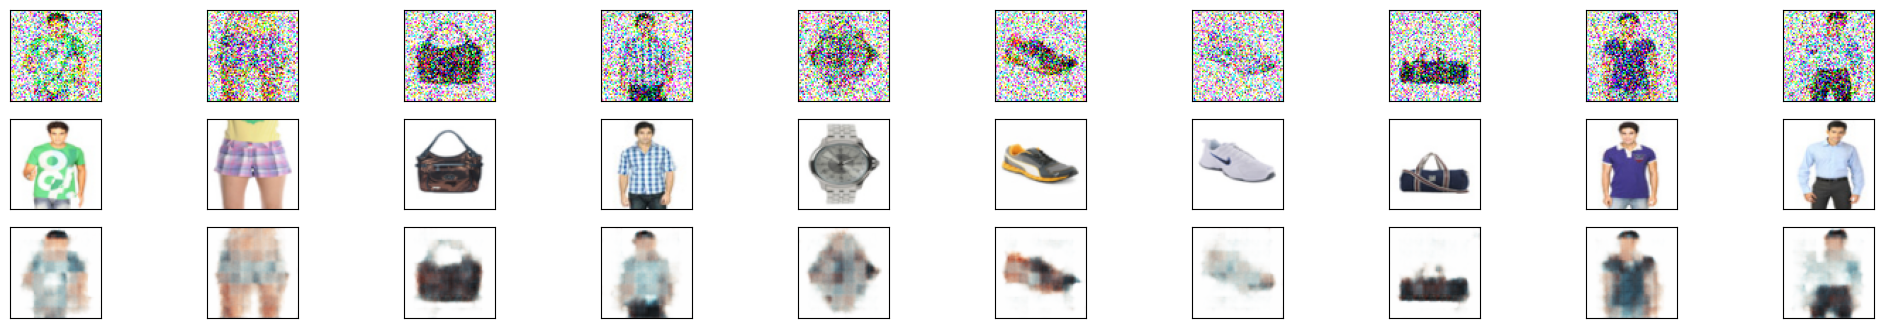

In [38]:
import matplotlib.pyplot as plt  # 导入 matplotlib 库，用于绘图
%matplotlib inline
# 在 Jupyter Notebook 中内嵌显示图像

# 从验证数据加载器中获取一个批次的测试图像
dataiter = iter(val_loader)  # 创建验证数据加载器的迭代器
noisy_images, original_images = next(dataiter)  # 获取下一个批次的数据（图像和标签）

print("测试集 images 形状: ", noisy_images.shape)  # 打印图像的形状，通常是 (batch_size, channels, height, width)

model = model.to(device)  # 将模型移动到指定的设备

noisy_images = noisy_images.to(device)  # 将噪声图像移动到指定的设备
print("测试集 noisy_images 形状: ", noisy_images.shape)  # 打印图像的形状，通常是 (batch_size, channels, height, width)

# 获取模型的输出（去噪后的图像）
output = model(noisy_images)  # 将噪声图像输入模型，得到去噪后的输出
print("测试集输出结果 output 形状: ", output.shape)  # 打印输出的形状，通常是 (batch_size, channels, height, width)

# 准备噪声图像用于显示
noisy_images = noisy_images.cpu().numpy()  # 将噪声图像从 PyTorch 张量转换为 NumPy 数组
print('noisy_imgs 转换为 numpy 数组后的形状: ', noisy_images.shape)  # 打印噪声图像的形状
noisy_images = np.moveaxis(noisy_images, 1, -1)  # 调整维度顺序，将通道维度移到最后一维，适配 matplotlib 的显示格式

# 将输出调整为批次图像的形状
output = output.view(batch_size, 3, 64, 64)  # 将输出张量调整为 (batch_size, channels, height, width) 的形状
# 使用 detach() 分离梯度信息，并将其转换为 NumPy 数组
output = output.detach().cpu().numpy()  # 将输出从 PyTorch 张量转换为 NumPy 数组
print('output 转换为 numpy 数组后的形状: ', output.shape)  # 打印输出的形状
output = np.moveaxis(output, 1, -1)  # 调整维度顺序，将通道维度移到最后一维，适配 matplotlib 的显示格式
print('output 的通道维度移到最后一维后的形状: ', output.shape)  # 打印调整后的输出形状

original_images = original_images.cpu().numpy().transpose((0, 2, 3, 1))
print("original_image shape: ", original_images.shape)

# 绘制前 10 张输入图像和重建图像
fig, axes = plt.subplots(nrows=3, ncols=10, sharex=True, sharey=True, figsize=(25,4))  # 创建 2 行 10 列的子图
# 第一行显示噪声图像，第二行显示重建图像
for imgs, row in zip([noisy_images, original_images, output], axes):  # 遍历噪声图像和重建图像
    for img, ax in zip(imgs, row):  # 遍历每张图像和对应的子图
        ax.imshow(np.squeeze(img))  # 显示图像，并去除多余的维度
        ax.get_xaxis().set_visible(False)  # 隐藏 x 轴
        ax.get_yaxis().set_visible(False)  # 隐藏 y 轴
plt.show()  # 显示图像